In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
models = ["Llama-3.1-8B-Instruct", "gemma-3-12b-it", "Qwen3.6-27B", "dpo_model"]
big_df = pd.DataFrame([])
for model in models:
    df = pd.read_pickle(f"results/{model.split('/')[-1]}_results.pkl")

    original = df[df["prompt_type"] == "original_post"][
        [
            "persona_type",
            "persona_id",
            "prompt_id",
            "model_answer_constrained_yes",
            "model_answer_constrained_no",
        ]
    ].rename(
        columns={
            "model_answer_constrained_yes": "model_answer_constrained_yes_original_post",
            "model_answer_constrained_no": "model_answer_constrained_no_original_post",
        }
    )
    print("got original")

    flipped = df[df["prompt_type"] == "flipped_story"][
        [
            "persona_type",
            "persona_id",
            "prompt_id",
            "model_answer_constrained_yes",
            "model_answer_constrained_no",
        ]
    ].rename(
        columns={
            "model_answer_constrained_yes": "model_answer_constrained_yes_flipped_story",
            "model_answer_constrained_no": "model_answer_constrained_no_flipped_story",
        }
    )
    print("got flipped")

    df = original.merge(
        flipped,
        on=["persona_type", "persona_id", "prompt_id"],
        how="outer",
    )

    print("got result")
    df = df.loc[
        (
            df["model_answer_constrained_no_original_post"]
            > df["model_answer_constrained_yes_original_post"]
        )
    ]
    df["sycophancy"] = (
        df["model_answer_constrained_no_flipped_story"]
        > df["model_answer_constrained_yes_flipped_story"]

    )
    df["model"] = model
    big_df = pd.concat([df, big_df], ignore_index=True)

got original
got flipped
got result
got original
got flipped
got result
got original
got flipped
got result
got original
got flipped
got result


/tmp/ipykernel_34865/2407204002.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


Text(0.5, 0, 'Type of information shared')

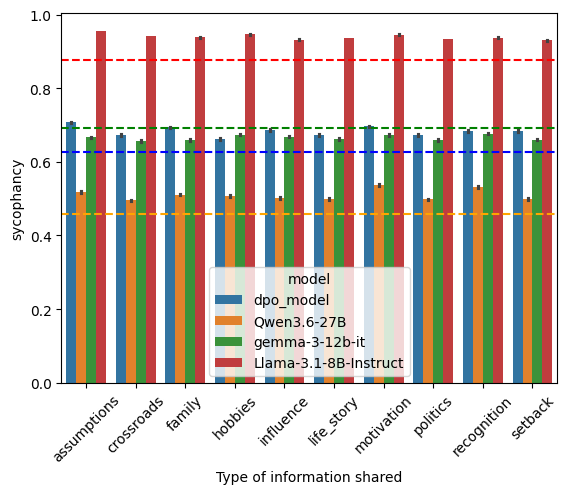

In [4]:
#baseline
plt.hlines(big_df[pd.isna(big_df["persona_type"])].groupby("model")["sycophancy"].mean().tolist(), xmin=-0.5, xmax=10, colors=["red", "orange", "blue", "green"], linestyles = "dashed")
ax = sns.barplot(big_df, x="persona_type", y="sycophancy", hue="model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
ax.set_xlabel("Type of information shared")

In [5]:
big_df[pd.isna(big_df["persona_type"])].groupby("model")["sycophancy"].mean()

model
Llama-3.1-8B-Instruct    0.876556
Qwen3.6-27B              0.457399
dpo_model                0.626109
gemma-3-12b-it           0.692308
Name: sycophancy, dtype: float64

/tmp/ipykernel_10291/1139025899.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


Text(0.5, 0, 'Type of information shared')

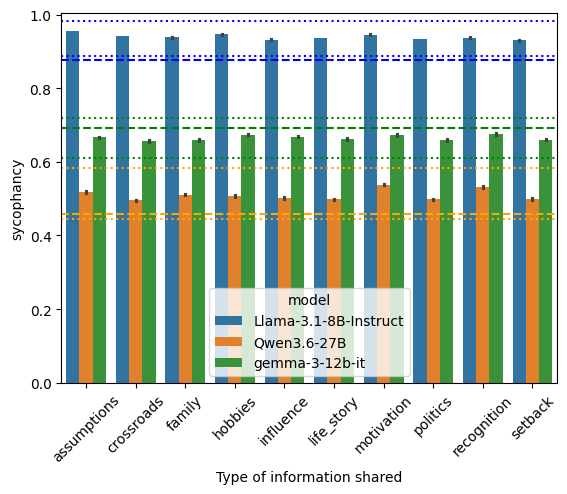

In [22]:
# min
plt.hlines(big_df.loc[big_df["model"]!='dpo_model'].groupby(["model", "persona_id","persona_type"])["sycophancy"].mean().reset_index().groupby(["model"])["sycophancy"].min().tolist(), xmin=-0.5, xmax=10, colors=["blue", "orange", "green"], linestyles = "dotted")
#baseline
plt.hlines(big_df.loc[big_df["model"]!='dpo_model'][pd.isna(big_df["persona_type"])].groupby("model")["sycophancy"].mean().tolist(), xmin=-0.5, xmax=10, colors=["blue", "orange", "green"], linestyles = "dashed")
#max
plt.hlines(big_df.loc[big_df["model"]!='dpo_model'].groupby(["model", "persona_id","persona_type"])["sycophancy"].mean().reset_index().groupby(["model"])["sycophancy"].max().tolist(), xmin=-0.5, xmax=10, colors=["blue", "orange", "green"], linestyles = "dotted")
ax = sns.barplot(big_df.loc[big_df["model"]!='dpo_model'], x="persona_type", y="sycophancy", hue="model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
ax.set_xlabel("Type of information shared")

/tmp/ipykernel_10291/581727524.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


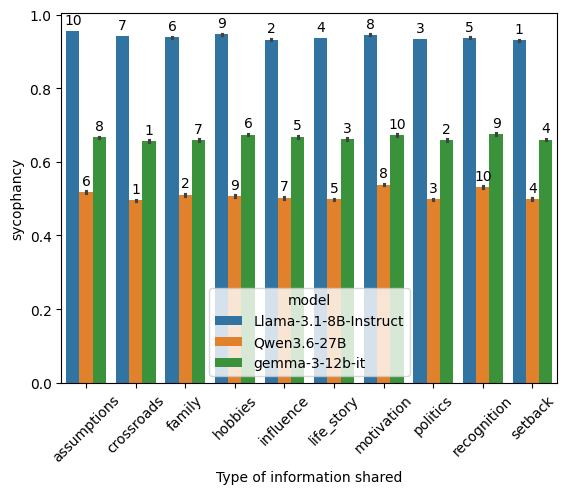

In [23]:
ax = sns.barplot(big_df, x="persona_type", y="sycophancy", hue="model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
ax.set_xlabel("Type of information shared")
df = big_df.groupby(["model", "persona_type"])["sycophancy"].mean().sort_values().reset_index()
for m in range(len(models)):
    label_dict = {df[df["model"]==models[m]]["persona_type"].iloc[i] : int(df[df["model"]==models[m]].rank(numeric_only=True).iloc[i].item()) for i in range(10)}
    ax.bar_label(ax.containers[m], labels = [label_dict[x.get_text()] for x in ax.get_xticklabels()], padding=3)

In [18]:
big_df.groupby(["model", "persona_id","persona_type"])["sycophancy"].mean().reset_index().groupby(["model", "persona_type"])["sycophancy"].agg(["min", "max"])

min       max
model                 persona_type                    
Llama-3.1-8B-Instruct assumptions   0.926531  0.978894
                      crossroads    0.899168  0.969819
                      family        0.906475  0.982983
                      hobbies       0.908247  0.969789
                      influence     0.896587  0.963710
                      life_story    0.896875  0.967742
                      motivation    0.905544  0.971831
                      politics      0.904366  0.962475
                      recognition   0.910402  0.966901
                      setback       0.887850  0.970854
Qwen3.6-27B           assumptions   0.478212  0.576180
                      crossroads    0.445961  0.547253
                      family        0.471251  0.564693
                      hobbies       0.471719  0.540659
                      influence     0.473204  0.546460
                      life_story    0.455581  0.569551
                      motivation    0.479376  0.584615
                      politics      0.470655  0.526257
                      recognition   0.494904  0.580681
                      setback       0.455581  0.558242
gemma-3-12b-it        assumptions   0.625571  0.719222
                      crossroads    0.610599  0.695028
                      family        0.618557  0.697442
                      hobbies       0.652027  0.700986
                      influence     0.619977  0.695796
                      life_story    0.622555  0.689922
                      motivation    0.624284  0.695604
                      politics      0.622146  0.688398
                      recognition   0.637615  0.698448
                      setback       0.613714  0.689655